# 01. PaySim 데이터 점검과 시간순 분할

**목적:** 공개 합성 금융거래 원본 전체를 PySpark로 점검하고, 같은 `step`을 유지하는
Train / Validation / Test 데이터셋을 Parquet으로 저장합니다.

- 데이터: [Kaggle · ealaxi/paysim1](https://www.kaggle.com/datasets/ealaxi/paysim1)
- 목표 비율: 거래 건수 기준 약 **60% / 20% / 20%** (시간순, 무작위 섞기 없음)
- 정답은 분포 감사에만 사용하고, 분할 경계 선택에는 사용하지 않습니다.
- 이 노트북은 연구용 분할 데이터를 만듭니다. 저장된 원본 컬럼에는 정답이 있으므로
  모델 특징과 Agent 입력은 별도 허용 목록으로 구성해야 합니다.
- 동일 `step` 내부의 실제 거래 순서는 알 수 없습니다. 향후 이력 특징은 반드시
  `history.step < current.step` 조건을 사용합니다.

프로젝트의 `.venv` 커널에서 **위에서 아래로 모두 실행**하세요.
전체 CSV를 Pandas에 올리지 않고 Spark로 집계하며, 작은 집계표만 Pandas로 변환합니다.


In [1]:
import csv
import hashlib
import json
import os
import platform
import shutil
import subprocess
import sys
import time
import uuid
import zipfile
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from pyspark import StorageLevel
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql import types as T

ROOT = next(
    (
        p
        for p in [Path.cwd(), *Path.cwd().parents]
        if (p / "pyproject.toml").is_file() and (p / "src/fds_agent").is_dir()
    ),
    None,
)
assert ROOT is not None, "프로젝트 루트 또는 notebooks 폴더에서 실행하세요."
RAW = ROOT / "data/raw"
# CSV가 여러 개라면 여기에 사용할 파일명을 지정하세요.
CSV_NAME = None
TRAIN_FRACTION = 0.60
VALIDATION_FRACTION = 0.20
SPARK_WORKERS = 2
DRIVER_MEMORY = "2g"
RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ") + "-" + uuid.uuid4().hex[:8]
REPORT_DIR = ROOT / "artifacts/reports" / RUN_ID
OUTPUT_DIR = ROOT / "data/processed/paysim_time_split" / RUN_ID
REPORT_DIR.mkdir(parents=True, exist_ok=False)
started = time.perf_counter()
print("Python:", sys.version.split()[0], "| 실행 파일:", sys.executable)
print("프로젝트:", ROOT)
print("실행 ID:", RUN_ID)

Matplotlib is building the font cache; this may take a moment.


Python: 3.11.14 | 실행 파일: /Users/yueun/Desktop/FDS-AI-Agent/.venv/bin/python
프로젝트: /Users/yueun/Desktop/FDS-AI-Agent
실행 ID: 20261117T045208Z-05da6abe


## 1. 원본 준비와 출처 기록

기존 CSV가 있으면 그대로 사용합니다. CSV가 없으면 `data/raw/paysim.zip` 또는
다운로드가 끝난 `paysim.zip.part`를 검사해 CSV 하나만 추출합니다.
손상된 ZIP, CSV 여러 개, 예상과 다른 컬럼은 조용히 넘어가지 않고 중단합니다.

원본은 수정하지 않으며 SHA-256과 파일 크기를 기록합니다. 파일 해시는 이번에 사용한
원본을 식별하기 위한 것으로, 게시자가 제공한 체크섬과 대조한 인증은 아닙니다.


In [2]:
RAW.mkdir(parents=True, exist_ok=True)
candidates = sorted(RAW.glob("*.csv"))
if CSV_NAME:
    csv_path = RAW / CSV_NAME
    assert csv_path.is_file(), f"CSV가 없습니다: {csv_path}"
elif len(candidates) == 1:
    csv_path = candidates[0]
elif len(candidates) > 1:
    raise ValueError("CSV가 여러 개입니다. CSV_NAME을 지정하세요.")
else:
    archive = RAW / "paysim.zip"
    partial = RAW / "paysim.zip.part"
    if not archive.exists() and partial.exists():
        assert zipfile.is_zipfile(partial), "다운로드가 완료된 ZIP이 아닙니다."
        with zipfile.ZipFile(partial) as zf:
            assert zf.testzip() is None, "ZIP 무결성 검사 실패"
        partial.rename(archive)
    if not archive.exists():
        raise FileNotFoundError(
            "Kaggle ealaxi/paysim1에서 받은 CSV 또는 paysim.zip을 data/raw/에 넣으세요."
        )
    with zipfile.ZipFile(archive) as zf:
        assert zf.testzip() is None, "ZIP 무결성 검사 실패"
        members = [m for m in zf.infolist() if m.filename.lower().endswith(".csv")]
        assert len(members) == 1, "ZIP 안에 CSV가 정확히 하나 있어야 합니다."
        member = members[0]
        assert shutil.disk_usage(RAW).free > member.file_size * 2, "추출 공간 부족"
        csv_path = RAW / Path(member.filename).name
        temporary_csv = csv_path.with_suffix(".csv.extracting")
        with zf.open(member) as source, temporary_csv.open("wb") as target:
            shutil.copyfileobj(source, target, length=1024 * 1024)
        temporary_csv.rename(csv_path)

EXPECTED_COLUMNS = [
    "step",
    "type",
    "amount",
    "nameOrig",
    "oldbalanceOrg",
    "newbalanceOrig",
    "nameDest",
    "oldbalanceDest",
    "newbalanceDest",
    "isFraud",
    "isFlaggedFraud",
]
with csv_path.open(newline="", encoding="utf-8-sig") as handle:
    assert next(csv.reader(handle)) == EXPECTED_COLUMNS, "예상과 다른 CSV 컬럼입니다."
sha256 = hashlib.sha256()
with csv_path.open("rb") as handle:
    for chunk in iter(lambda: handle.read(8 * 1024 * 1024), b""):
        sha256.update(chunk)
source_info = {
    "dataset": "ealaxi/paysim1",
    "source_url": "https://www.kaggle.com/datasets/ealaxi/paysim1",
    "download_url": "https://www.kaggle.com/api/v1/datasets/download/ealaxi/paysim1",
    "csv": str(csv_path.relative_to(ROOT)),
    "bytes": csv_path.stat().st_size,
    "sha256": sha256.hexdigest(),
}
print(json.dumps(source_info, indent=2, ensure_ascii=False))

{
  "dataset": "ealaxi/paysim1",
  "source_url": "https://www.kaggle.com/datasets/ealaxi/paysim1",
  "download_url": "https://www.kaggle.com/api/v1/datasets/download/ealaxi/paysim1",
  "csv": "data/raw/PS_20174392719_1491204439457_log.csv",
  "bytes": 493534783,
  "sha256": "16910f90577b0d981bf8ff289714510bb89bc71bff7d3f220f024e287e4eea6b"
}


## 2. Spark 로딩과 품질 검사

명시적 스키마와 `FAILFAST`로 읽어 형식 오류를 감지합니다. 결측, NaN/무한대,
음수 금액·잔액, 유효하지 않은 레이블·거래 유형은 검사 실패로 처리합니다.
잔액 `0`은 결측으로 간주하지 않습니다. 이번 단계에서는 임의의 행 삭제나 중복 제거를 하지 않습니다.


In [3]:
if sys.platform == "darwin" and not os.environ.get("JAVA_HOME"):
    os.environ["JAVA_HOME"] = subprocess.check_output(
        ["/usr/libexec/java_home", "-v", "17"], text=True
    ).strip()
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ.setdefault("SPARK_LOCAL_IP", "127.0.0.1")
spark = (
    SparkSession.builder.master(f"local[{SPARK_WORKERS}]")
    .appName("FDS-PaySim-EDA-Split")
    .config("spark.driver.memory", DRIVER_MEMORY)
    .config("spark.sql.shuffle.partitions", "8")
    .config("spark.ui.enabled", "false")
    .config("spark.driver.bindAddress", "127.0.0.1")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")
print("Spark:", spark.version)

numeric_columns = ["amount", "oldbalanceOrg", "newbalanceOrig", "oldbalanceDest", "newbalanceDest"]
integer_columns = ["step", "isFraud", "isFlaggedFraud"]
schema = T.StructType(
    [
        T.StructField(
            name,
            T.IntegerType()
            if name in integer_columns
            else T.DoubleType()
            if name in numeric_columns
            else T.StringType(),
            True,
        )
        for name in EXPECTED_COLUMNS
    ]
)
df = (
    spark.read.option("header", True)
    .option("mode", "FAILFAST")
    .option("enforceSchema", False)
    .schema(schema)
    .csv(str(csv_path))
    .persist(StorageLevel.MEMORY_AND_DISK)
)
quality = (
    df.agg(
        F.count("*").alias("rows"),
        *[
            F.sum(F.when(F.col(c).isNull(), 1).otherwise(0)).alias(f"null_{c}")
            for c in EXPECTED_COLUMNS
        ],
        *[
            F.sum(F.when(F.isnan(c) | (F.abs(F.col(c)) == float("inf")), 1).otherwise(0)).alias(
                f"nonfinite_{c}"
            )
            for c in numeric_columns
        ],
        *[
            F.sum(F.when(F.col(c) < 0, 1).otherwise(0)).alias(f"negative_{c}")
            for c in numeric_columns
        ],
        F.sum(F.when(F.col("step") < 1, 1).otherwise(0)).alias("invalid_step"),
        *[
            F.sum(F.when(~F.col(c).isin(0, 1), 1).otherwise(0)).alias(f"invalid_{c}")
            for c in ["isFraud", "isFlaggedFraud"]
        ],
        F.sum(
            F.when(
                ~F.col("type").isin("PAYMENT", "TRANSFER", "CASH_OUT", "DEBIT", "CASH_IN"), 1
            ).otherwise(0)
        ).alias("invalid_type"),
        *[
            F.sum(F.when(F.trim(F.col(c)) == "", 1).otherwise(0)).alias(f"empty_{c}")
            for c in ["nameOrig", "nameDest"]
        ],
    )
    .first()
    .asDict()
)
assert quality["rows"] > 0, "원본 데이터가 비어 있습니다."
issues = {key: value for key, value in quality.items() if key != "rows" and value != 0}
display(pd.DataFrame([quality]).T.rename(columns={0: "count"}))
assert not issues, f"품질 검사 실패: {issues}"
print(f"품질 검사 통과: {quality['rows']:,}건")

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/17 13:52:12 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark: 4.0.1


,count
rows,6362620
null_step,0
null_type,0
null_amount,0
null_nameOrig,0
null_oldbalanceOrg,0
null_newbalanceOrig,0
null_nameDest,0
null_oldbalanceDest,0
null_newbalanceDest,0


품질 검사 통과: 6,362,620건


## 3. 전체·거래 유형·시간별 분포

사기 비율은 시간에 따라 다를 수 있습니다. 아래 분포는 데이터 상태를 이해하기 위한 감사 결과이며,
테스트 분포에 맞춰 모델이나 임계값을 튜닝하지 않습니다.


In [4]:
overall = (
    df.agg(
        F.count("*").alias("rows"),
        F.sum("isFraud").alias("fraud"),
        F.min("step").alias("min_step"),
        F.max("step").alias("max_step"),
        F.countDistinct("step").alias("distinct_steps"),
        F.min("amount").alias("min_amount"),
        F.max("amount").alias("max_amount"),
        F.avg("amount").alias("mean_amount"),
    )
    .first()
    .asDict()
)
overall["normal"] = overall["rows"] - overall["fraud"]
overall["fraud_rate"] = overall["fraud"] / overall["rows"]
by_type = (
    df.groupBy("type")
    .agg(
        F.count("*").alias("rows"),
        F.sum("isFraud").alias("fraud"),
        F.avg("amount").alias("mean_amount"),
    )
    .orderBy("type")
    .toPandas()
)
by_type["fraud_rate"] = by_type["fraud"] / by_type["rows"]
by_step = (
    df.groupBy("step")
    .agg(F.count("*").alias("rows"), F.sum("isFraud").alias("fraud"))
    .orderBy("step")
    .toPandas()
)
by_step["fraud_rate"] = by_step["fraud"] / by_step["rows"]
by_step["cumulative_rows"] = by_step["rows"].cumsum()
by_step["cumulative_fraction"] = by_step["cumulative_rows"] / overall["rows"]
display(pd.DataFrame([overall]))
display(by_type)
display(by_step.head(10))
by_type.to_csv(REPORT_DIR / "distribution_by_type.csv", index=False)
by_step.to_csv(REPORT_DIR / "distribution_by_step.csv", index=False)

,rows,fraud,min_step,max_step,distinct_steps,min_amount,max_amount,mean_amount,normal,fraud_rate
0,6362620,8213,1,743,743,0.0,92445516.64,179861.903549,6354407,0.001291


,type,rows,fraud,mean_amount,fraud_rate
0,CASH_IN,1399284,0,168920.242004,0.000000
1,CASH_OUT,2237500,4116,176273.964346,0.001840
2,DEBIT,41432,0,5483.665314,0.000000
3,PAYMENT,2151495,0,13057.604660,0.000000
4,TRANSFER,532909,4097,910647.009645,0.007688


,step,rows,fraud,fraud_rate,cumulative_rows,cumulative_fraction
0,1,2708,16,0.005908,2708,0.000426
1,2,1014,8,0.007890,3722,0.000585
2,3,552,4,0.007246,4274,0.000672
3,4,565,10,0.017699,4839,0.000761
4,5,665,6,0.009023,5504,0.000865
5,6,1660,22,0.013253,7164,0.001126
6,7,6837,12,0.001755,14001,0.002201
7,8,21097,12,0.000569,35098,0.005516
8,9,37628,19,0.000505,72726,0.011430
9,10,35991,11,0.000306,108717,0.017087


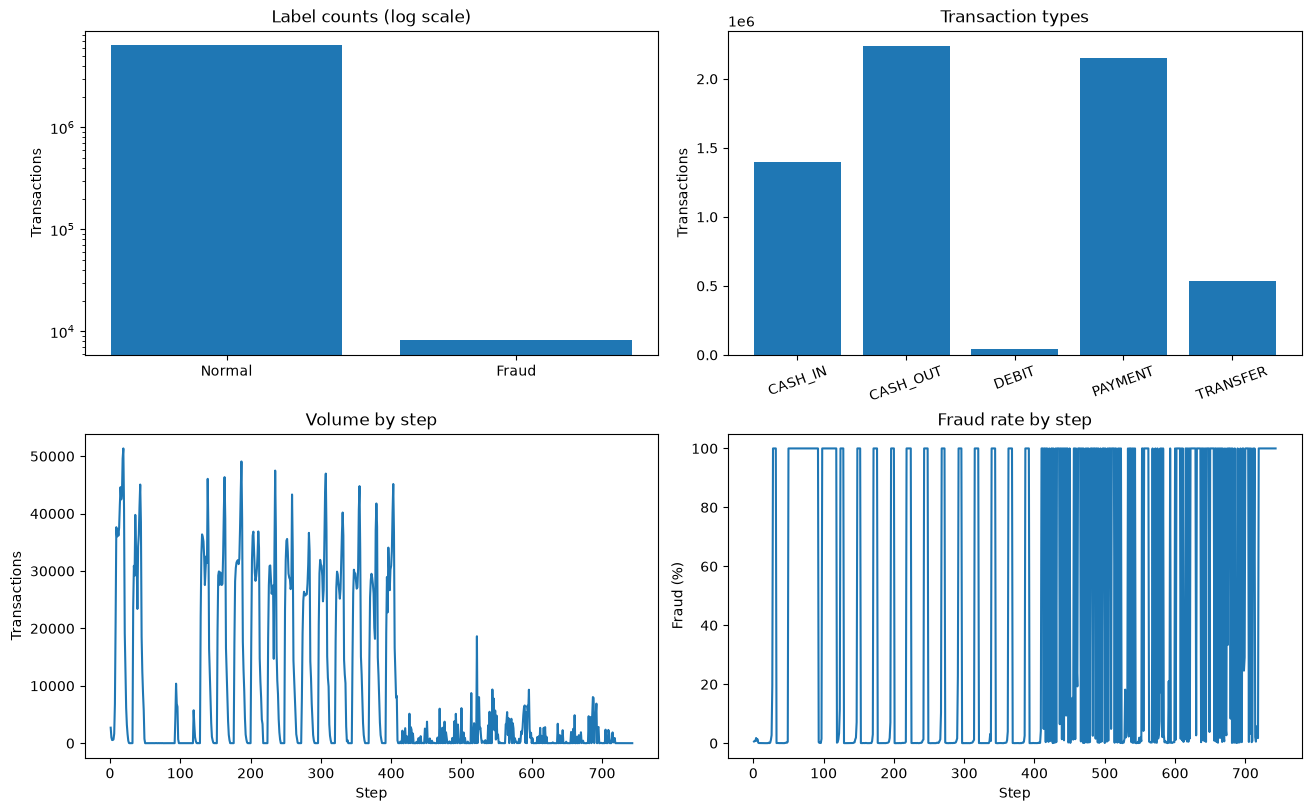

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8), constrained_layout=True)
axes[0, 0].bar(["Normal", "Fraud"], [overall["normal"], overall["fraud"]])
axes[0, 0].set_yscale("log")
axes[0, 0].set(title="Label counts (log scale)", ylabel="Transactions")
axes[0, 1].bar(by_type["type"], by_type["rows"])
axes[0, 1].tick_params(axis="x", rotation=20)
axes[0, 1].set(title="Transaction types", ylabel="Transactions")
axes[1, 0].plot(by_step["step"], by_step["rows"])
axes[1, 0].set(title="Volume by step", xlabel="Step", ylabel="Transactions")
axes[1, 1].plot(by_step["step"], by_step["fraud_rate"] * 100)
axes[1, 1].set(title="Fraud rate by step", xlabel="Step", ylabel="Fraud (%)")
fig.savefig(REPORT_DIR / "distribution.png", dpi=150)
plt.show()
plt.close(fig)

## 4. 시간순 분할 경계 선택

`step`별 누적 건수가 60%, 80%에 가장 가까워지는 경계를 순서대로 선택합니다.
동률이면 더 이른 경계를 사용합니다. 각 구간에는 최소 하나의 `step`이 있어야 합니다.
이는 같은 시간대의 거래를 분리하지 않는 **결정적 근사 분할**이며 정확히 60:20:20일 필요는 없습니다.
경계 선택 함수에는 사기 레이블을 전달하지 않습니다.


In [6]:
def choose_boundaries(step_counts, train_fraction=0.60, validation_fraction=0.20):
    if not (
        0 < train_fraction < 1
        and 0 < validation_fraction < 1
        and train_fraction + validation_fraction < 1
    ):
        raise ValueError("각 분할의 비율은 양수이며 합이 1보다 작아야 합니다.")
    counts = step_counts[["step", "rows"]].sort_values("step").reset_index(drop=True)
    if (
        len(counts) < 3
        or counts["step"].duplicated().any()
        or counts.isna().any().any()
        or (counts["rows"] <= 0).any()
    ):
        raise ValueError("3개 이상의 고유 step과 양수 건수가 필요합니다.")
    cumulative = counts["rows"].cumsum() / counts["rows"].sum()
    train_index = (cumulative.iloc[:-2] - train_fraction).abs().idxmin()
    val_candidates = cumulative.iloc[train_index + 1 : -1]
    validation_index = (val_candidates - train_fraction - validation_fraction).abs().idxmin()
    return int(counts.loc[train_index, "step"]), int(counts.loc[validation_index, "step"])


# 경계 조건 검증: 균등, 시간 공백, 한 step에 쏠린 분포, 잘못된 입력.
assert choose_boundaries(pd.DataFrame({"step": range(1, 11), "rows": [10] * 10})) == (6, 8)
assert choose_boundaries(pd.DataFrame({"step": [1, 7, 20], "rows": [98, 1, 1]})) == (1, 7)
for invalid in [
    pd.DataFrame({"step": [1, 2], "rows": [1, 1]}),
    pd.DataFrame({"step": [1, 1, 2], "rows": [1, 1, 1]}),
]:
    try:
        choose_boundaries(invalid)
    except ValueError:
        pass
    else:
        raise AssertionError("잘못된 분할 입력을 거부해야 합니다.")
train_end, validation_end = choose_boundaries(
    by_step[["step", "rows"]], TRAIN_FRACTION, VALIDATION_FRACTION
)
print(f"Train: step <= {train_end}")
print(f"Validation: {train_end} < step <= {validation_end}")
print(f"Test: step > {validation_end}")

Train: step <= 281
Validation: 281 < step <= 354
Test: step > 354


,split,rows,fraud,min_step,max_step,distinct_steps,normal,row_fraction,fraud_rate
0,train,3820599,3193,1,281,281,3817406,0.600476,0.000836
1,validation,1248498,762,282,354,73,1247736,0.196224,0.000610
2,test,1293523,4258,355,743,389,1289265,0.203300,0.003292


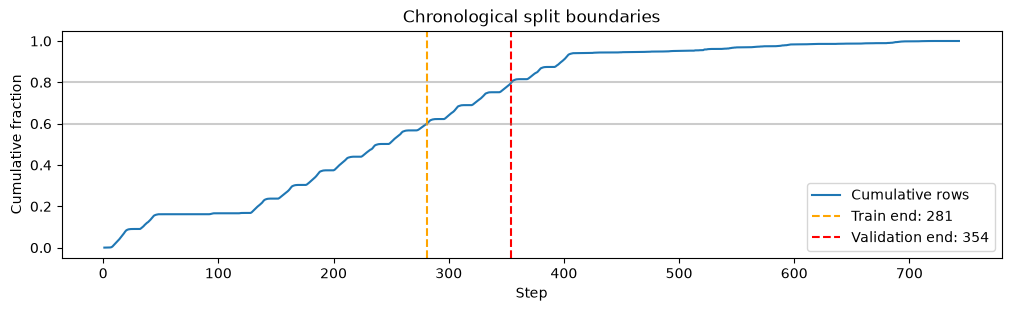

In [7]:
split_df = df.withColumn(
    "split",
    F.when(F.col("step") <= train_end, F.lit("train"))
    .when(F.col("step") <= validation_end, F.lit("validation"))
    .otherwise(F.lit("test")),
)
split_summary = (
    split_df.groupBy("split")
    .agg(
        F.count("*").alias("rows"),
        F.sum("isFraud").alias("fraud"),
        F.min("step").alias("min_step"),
        F.max("step").alias("max_step"),
        F.countDistinct("step").alias("distinct_steps"),
    )
    .toPandas()
    .set_index("split")
    .loc[["train", "validation", "test"]]
    .reset_index()
)
split_summary["normal"] = split_summary["rows"] - split_summary["fraud"]
split_summary["row_fraction"] = split_summary["rows"] / overall["rows"]
split_summary["fraud_rate"] = split_summary["fraud"] / split_summary["rows"]
assert int(split_summary["rows"].sum()) == overall["rows"]
assert int(split_summary["fraud"].sum()) == overall["fraud"]
assert (split_summary["rows"] > 0).all()
assert split_summary.loc[0, "max_step"] < split_summary.loc[1, "min_step"]
assert split_summary.loc[1, "max_step"] < split_summary.loc[2, "min_step"]
assert (
    split_df.groupBy("step").agg(F.countDistinct("split").alias("n")).filter("n != 1").count() == 0
), "동일 step이 여러 구간에 포함되었습니다."
display(split_summary)
if (split_summary["fraud"] == 0).any():
    print("주의: 사기가 없는 구간이 있습니다. 평가 지표 계산 전에 확인하세요.")
split_summary.to_csv(REPORT_DIR / "split_summary.csv", index=False)

fig, ax = plt.subplots(figsize=(10, 3), constrained_layout=True)
ax.plot(by_step["step"], by_step["cumulative_fraction"], label="Cumulative rows")
ax.axvline(train_end, color="orange", linestyle="--", label=f"Train end: {train_end}")
ax.axvline(validation_end, color="red", linestyle="--", label=f"Validation end: {validation_end}")
ax.axhline(0.6, color="gray", alpha=0.4)
ax.axhline(0.8, color="gray", alpha=0.4)
ax.set(xlabel="Step", ylabel="Cumulative fraction", title="Chronological split boundaries")
ax.legend()
fig.savefig(REPORT_DIR / "split_boundaries.png", dpi=150)
plt.show()
plt.close(fig)

## 5. Parquet 저장과 재검증

매번 새로운 실행 ID 경로를 사용해 기존 결과를 덮어쓰지 않습니다.
`split=train`, `split=validation`, `split=test` 파티션으로 저장합니다.
Parquet 파일 내부나 파일 간의 순서는 보장되지 않으므로 배치 재생 시 `step`을 기준으로
명시적으로 정렬해야 합니다. 같은 `step` 내부의 순서를 실제 발생 순서라고 해석하지 마세요.

저장 후 구간별 건수·사기 건수·최소/최대 step을 다시 읽어 비교하고,
전체 행의 다중집합 차집합을 양방향 검사하여 중복 행을 포함한 보존 여부를 확인합니다.
검증에 성공한 실행만 `manifest.json`을 만듭니다.


In [8]:
assert not OUTPUT_DIR.exists(), "이미 존재하는 실행 경로입니다. 새 실행 ID를 사용하세요."
parquet_path = OUTPUT_DIR / "transactions"
write_started = time.perf_counter()
(
    split_df.repartition(8)
    .write.mode("errorifexists")
    .partitionBy("split")
    .parquet(str(parquet_path))
)
restored = spark.read.parquet(str(parquet_path))
restored_summary = (
    restored.groupBy("split")
    .agg(
        F.count("*").alias("rows"),
        F.sum("isFraud").alias("fraud"),
        F.min("step").alias("min_step"),
        F.max("step").alias("max_step"),
        F.countDistinct("step").alias("distinct_steps"),
    )
    .toPandas()
    .sort_values("split")
    .reset_index(drop=True)
)
expected_summary = (
    split_summary[restored_summary.columns].sort_values("split").reset_index(drop=True)
)
pd.testing.assert_frame_equal(restored_summary, expected_summary, check_dtype=False)
assert (
    restored.groupBy("step").agg(F.countDistinct("split").alias("n")).filter("n != 1").count() == 0
)
columns = EXPECTED_COLUMNS + ["split"]
assert split_df.select(columns).exceptAll(restored.select(columns)).limit(1).count() == 0
assert restored.select(columns).exceptAll(split_df.select(columns)).limit(1).count() == 0
write_and_verify_seconds = time.perf_counter() - write_started
print("Parquet 재검증 통과: 행 보존, 레이블 건수, 시간 경계, 동일 step 분리 없음")
print(parquet_path)

Parquet 재검증 통과: 행 보존, 레이블 건수, 시간 경계, 동일 step 분리 없음
/Users/yueun/Desktop/FDS-AI-Agent/data/processed/paysim_time_split/20261117T045208Z-05da6abe/transactions


In [9]:
manifest = {
    "run_id": RUN_ID,
    "completed_at_utc": datetime.now(timezone.utc).isoformat(),
    "source": source_info,
    "versions": {
        "python": platform.python_version(),
        "spark": spark.version,
        "pandas": pd.__version__,
    },
    "quality": quality,
    "overall": overall,
    "split_policy": {
        "method": "nearest_cumulative_row_fraction_by_step_sequential",
        "target_fractions": {
            "train": TRAIN_FRACTION,
            "validation": VALIDATION_FRACTION,
            "test": 1 - TRAIN_FRACTION - VALIDATION_FRACTION,
        },
        "train_end_step": train_end,
        "validation_end_step": validation_end,
        "boundary_uses_labels": False,
        "same_step_crosses_splits": False,
        "history_rule": "history.step < current.step",
    },
    "splits": json.loads(split_summary.to_json(orient="records")),
    "parquet_path": str(parquet_path.relative_to(ROOT)),
    "report_path": str(REPORT_DIR.relative_to(ROOT)),
    "contains_labels": True,
    "verified": True,
    "verification": "aggregate equality + bidirectional exceptAll including duplicates",
    "elapsed_seconds": round(time.perf_counter() - started, 2),
    "write_and_verify_seconds": round(write_and_verify_seconds, 2),
}
manifest_text = json.dumps(manifest, ensure_ascii=False, indent=2)
(OUTPUT_DIR / "manifest.json").write_text(manifest_text, encoding="utf-8")
(REPORT_DIR / "manifest.json").write_text(manifest_text, encoding="utf-8")
print(
    f"전체 {overall['rows']:,}건 / 사기 {overall['fraud']:,}건"
    f" / 사기 비율 {overall['fraud_rate']:.4%}"
)
print("결과 manifest:", OUTPUT_DIR / "manifest.json")
print("집계표와 그래프:", REPORT_DIR)
print("총 소요 시간(초):", manifest["elapsed_seconds"])
df.unpersist()
spark.stop()

전체 6,362,620건 / 사기 8,213건 / 사기 비율 0.1291%
결과 manifest: /Users/yueun/Desktop/FDS-AI-Agent/data/processed/paysim_time_split/20261117T045208Z-05da6abe/manifest.json
집계표와 그래프: /Users/yueun/Desktop/FDS-AI-Agent/artifacts/reports/20261117T045208Z-05da6abe
총 소요 시간(초): 56.48


## 다음 작업

1. 거래 시점에 이용 가능한 컬럼만 선택하고, 과거 `step`만 사용하는 특징 생성 노트북을 작성합니다.
2. Train으로 LightGBM을 학습하고 Validation으로 모델·임계값을 결정합니다.
3. 고정된 모델을 Test로 최종 평가한 뒤, 정답을 분리한 배치 재생 데이터를 만듭니다.

`isFraud`, `isFlaggedFraud`, 거래 이후 잔액은 초기 모델 특징에서 제외합니다.
계좌 ID는 이력 조회에 사용하며, Agent에는 정답이 포함된 연구용 Parquet을 직접 넘기지 않습니다.

참고: [PySpark 4.0.1 설치](https://spark.apache.org/docs/4.0.1/api/python/getting_started/install.html),
[노트북 실행과 출력 저장](https://nbclient.readthedocs.io/en/latest/client.html)
